# COMP5005 - Fundamentas of Programming
## Assignment: Smart Orchard WA Analysis & Showcase

* **Student Name:** Nicolas Belles
* **Student ID:** 24210773
* **Date:** October 2026

---
### Overview
This notebook presents the execution, unit verificarion, and comparative showcase scenarios for the **Smart Orchard WA** multi-robot automated harvesting simulation. All underlying core logic is imported modularly from `entities.py`, `farm.py`, and `simulation.py`.

In [1]:
# Enable inline plotting in Jupyter Notebook
%matplotlib inline

# Imports
import os
import csv
import matplotlib.pyplot as plt
# modular project classes
from entities import CropBlock, Robot
from farm import Farm
from simulation import Simulation

## Unit & Component Testing

In this section, we verify:
1. Map loading and parsing from `farmn1.csv`
2. Accesssible route computatuin via Breadh-First Search (BFS).
3. Robot target selection and state transition.
4. Farm topology accessiblity validation.

In [2]:
# Load map and settings
params_test = {
    "crop_quantity": 5,
    "crop_ready_timestep": 0,
    "robot_count": 2,
    "timesteps": 30
}

test_farm = Farm()
test_farm.load_map("farm1.csv", params_test)

# Instantiate robots at assigned depots
test_robots = [
    Robot(robot_id=i+1, depot=test_farm.depots[i % len(test_farm.depots)])
    for i in range(params_test["robot_count"])
]

# validate farm accessibility and route connectivity
test_farm.validate(test_robots)

print(
    f"Farm loaded successfully with the following dimensions:{test_farm.rows}x{test_farm.cols}")
print(
    f"Total Depots: {len(test_farm.depots)} | Total Crop Blocks: {len(test_farm.crop_blocks)}")
print(
    "Validation Check: PASSED - All crops and robots have valid driveable access .")

Farm loaded successfully with the following dimensions:5x6
Total Depots: 1 | Total Crop Blocks: 5
Validation Check: PASSED - All crops and robots have valid driveable access .


## Reusable Visualisation Utility

We defin a modular helper function `plot_simulation_results()` to generate double-panel figures comparing crate progression and delivery throughput.

In [ ]:
def plot_simulation_results(sim, title_suffix=""):
    """
    Generate a two-panel plot for a completed simulation run.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    timesteps = sim.history["timestep"]

    # Left Subplot: Create Quantities Over Time
    ax1.plot(timesteps, sim.history["delivered"],
             label="Delivered Crates", color='#2ca02c', linewidth=2.5)
    ax1.plot(timesteps, sim.history["unharvested"],
             label="Unharvested Crates", color='#d62728', linewidth=2.5)
    ax1.plot(timesteps, sim.history["carried"], label="Carried Crates",
             color='#ff7f0e', linewidth=2.5, linestyle='--')

    ax1.set_title(
        f"Crate Conservation & Progress {title_suffix}", fontweight='bold')
    ax1.set_xlabel("Elapsed Timesteps")
    ax1.set_ylabel("Crate Quantities")
    ax1.legend(frameon=True, facecolor='white', edgecolor='none')
    ax1.grid(True, linestyle=':', alpha=0.6)

    # Right Subplot: Throughput Efficiency
    ax2.plot(timesteps, sim.history["throughput"],
             label="Throughput (crates/step)", color='#1f77b4', linewidth=2.5)
    ax2.set_title(
        f"Delivery Throughput Rate {title_suffix}", fontweight='bold')
    ax2.set_xlabel("Elapsed Timesteps")
    ax2.set_ylabel("Throughput (crates/step)")
    ax2.legend(frameon=True, facecolor='white', edgecolor='none')
    ax2.grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

## Scenario 1: Baseline Simulation (`farm1.csv`)

Running the baseline simulation configured with default parameters (2 robots, 30 timesteps, ripe criops from timestep 0 )


Scenario 1 Compleated: Delivered 9 of 25 initial crates.


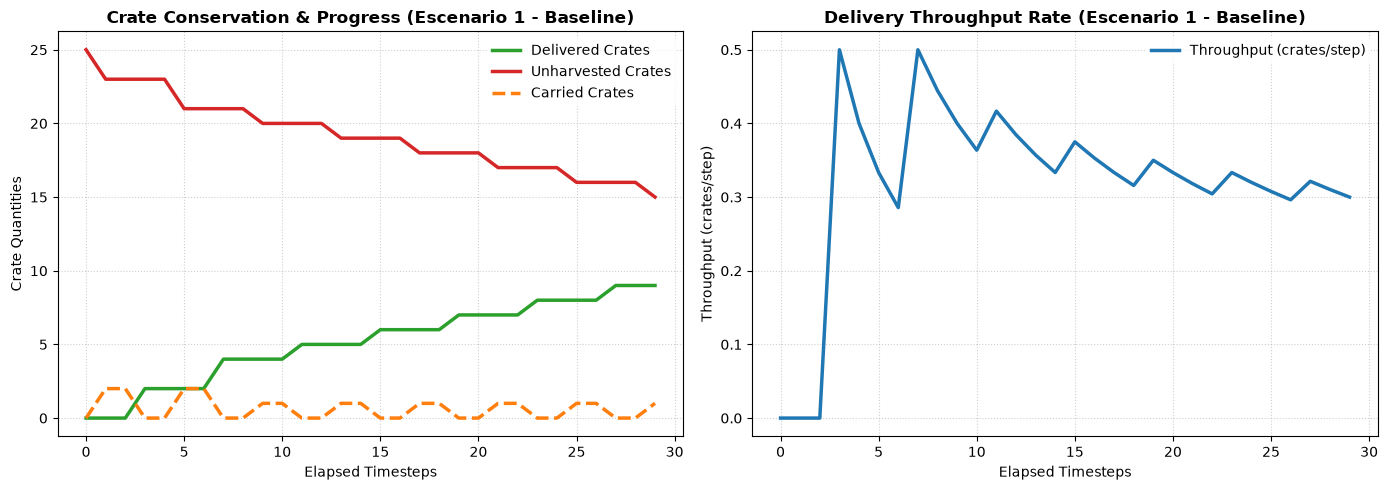

In [8]:
# Scenario 1: Baseline Simulation (farm1.csv)
params_scen1 = {
    "crop_quantity": 5,
    "crop_ready_timestep": 0,
    "robot_count": 2,
    "timesteps": 30
}

scen1_farm = Farm()
scen1_farm.load_map("farm1.csv", params_scen1)

scen1_robots = [
    Robot(robot_id=i+1, depot=scen1_farm.depots[i % len(scen1_farm.depots)])
    for i in range(params_scen1["robot_count"])
]

scen1_farm.validate(scen1_robots)
scen1_sim = Simulation(scen1_farm, scen1_robots, timesteps=30)
scen1_sim.run(interactive=False)

print(
    f"Scenario 1 Compleated: Delivered {scen1_sim.delivered_crates} of {scen1_sim.initial_crates} initial crates.")
plot_simulation_results(scen1_sim, title_suffix="(Escenario 1 - Baseline)")

## Scenario 2: Robot Fleet Comparision (1 vs 2 vs 4 Robots)

Evaluating performance bottlenecks and harvesting rate by varying the number of deployed robots on the same orchard topology.

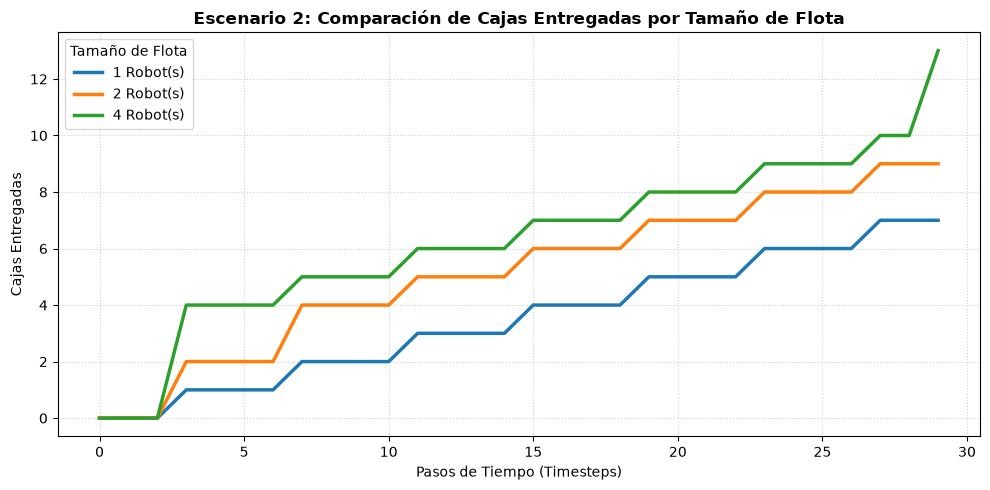

In [5]:
robot_counts = [1, 2, 4]
results_scen2 = {}

plt.figure(figsize=(10, 5))

for r_count in robot_counts:
    farm_s2 = Farm()
    farm_s2.load_map("farm1.csv", params_scen1)

    robots_s2 = [
        Robot(robot_id=i+1, depot=farm_s2.depots[i % len(farm_s2.depots)])
        for i in range(r_count)
    ]
    farm_s2.validate(robots_s2)

    sim_s2 = Simulation(farm_s2, robots_s2, timesteps=30)
    sim_s2.run(interactive=False)

    results_scen2[r_count] = sim_s2
    plt.plot(sim_s2.history["timestep"], sim_s2.history["delivered"],
             label=f"{r_count} Robot(s)", linewidth=2.5)

plt.title("Escenario 2: Comparación de Cajas Entregadas por Tamaño de Flota",
          fontweight="bold")
plt.xlabel("Pasos de Tiempo (Timesteps)")
plt.ylabel("Cajas Entregadas")
plt.legend(title="Tamaño de Flota", frameon=True)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

## Scenario 3: Varying Crop Readiness TimeSteps

Analyzing system responsiveness when crop mature at differnt times(`ready_timestep = 0` vs `ready_timesteps =10`).

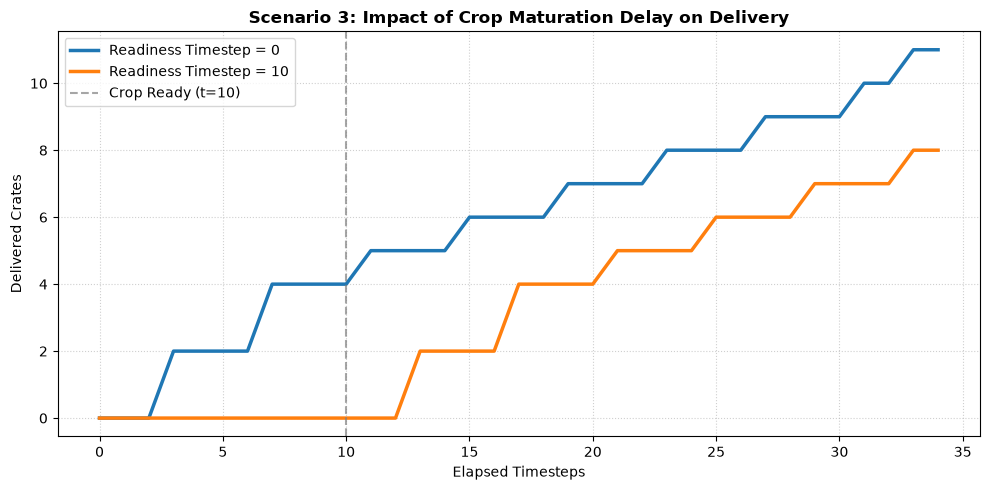

In [6]:
readiness_times = [0, 10]

plt.figure(figsize=(10, 5))

for ready_ts in readiness_times:
    params_s3 = {
        "crop_quantity": 5,
        "crop_ready_timestep": ready_ts,
        "robot_count": 2,
        "timesteps": 35
    }

    farm_s3 = Farm()
    farm_s3.load_map("farm1.csv", params_s3)

    robots_s3 = [
        Robot(robot_id=i+1, depot=farm_s3.depots[i % len(farm_s3.depots)])
        for i in range(2)
    ]
    farm_s3.validate(robots_s3)

    sim_s3 = Simulation(farm_s3, robots_s3, timesteps=35)
    sim_s3.run(interactive=False)

    plt.plot(
        sim_s3.history["timestep"],
        sim_s3.history["delivered"],
        label=f"Readiness Timestep = {ready_ts}",
        linewidth=2.5
    )

plt.title("Scenario 3: Impact of Crop Maturation Delay on Delivery",
          fontweight="bold")
plt.xlabel("Elapsed Timesteps")
plt.ylabel("Delivered Crates")
plt.axvline(x=10, color="gray", linestyle="--",
            alpha=0.7, label="Crop Ready (t=10)")
plt.legend(frameon=True)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()